In [29]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')

# Display the first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [30]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
df.info()

# Check first 5 rows
df.head()

Dataset Shape: (4340, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [31]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Number of Duplicate Rows:
763


In [32]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Check updated dataset shape
print("Dataset Shape After Removing Duplicates:", df.shape)

# Verify duplicates are removed
print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (3577, 8)
Remaining Duplicates: 0


Check categorical values

In [33]:
# Check unique values in categorical columns
categorical_cols = ['fuel', 'seller_type', 'transmission', 'owner']

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


fuel:
['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']

seller_type:
['Individual' 'Dealer' 'Trustmark Dealer']

transmission:
['Manual' 'Automatic']

owner:
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


Feature Engineering – Calculate Car Age

In [34]:
# Calculate car age
df['car_age'] = 2026 - df['year']

df[['year', 'car_age']].head()

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12


In [35]:
df['brand'] = df['name'].apply(
    lambda x: 'Land Rover' if x.startswith('Land Rover')
    else x.split()[0]
)

In [36]:
# Statistical summary of numerical columns
df[['selling_price', 'km_driven', 'car_age']].describe()

,selling_price,km_driven,car_age
count,3.577000e+03,3577.000000,3577.000000
mean,4.739125e+05,69250.545709,13.037462
std,5.093018e+05,47579.940016,4.251759
min,2.000000e+04,1.000000,6.000000
25%,2.000000e+05,36000.000000,10.000000
50%,3.500000e+05,60000.000000,13.000000
75%,6.000000e+05,90000.000000,16.000000
max,8.900000e+06,806599.000000,34.000000


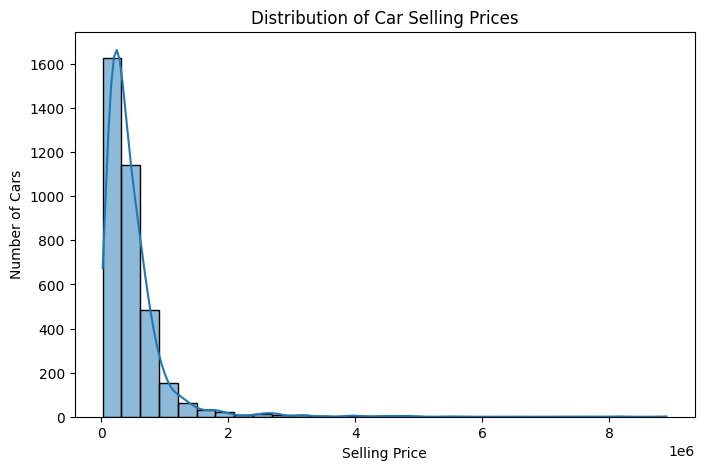

In [37]:
# Distribution of selling prices
plt.figure(figsize=(8, 5))

sns.histplot(df['selling_price'], bins=30, kde=True)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')

plt.show()

observation:

"The selling price distribution is positively skewed. Most cars are sold at relatively lower prices, while a few expensive cars increase the overall price range."

Selling price vs Fuel Type

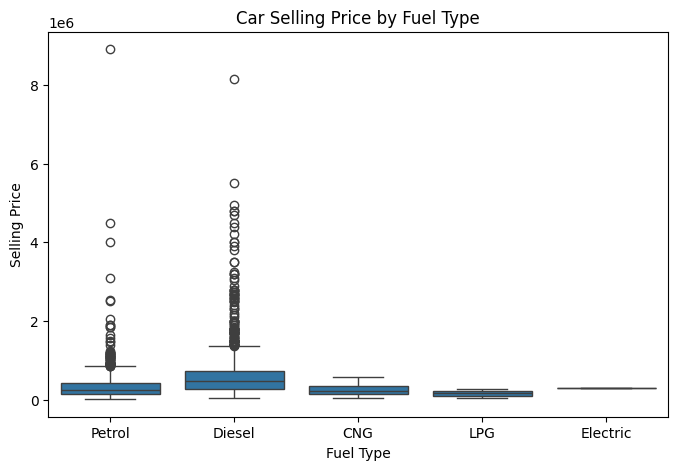

In [38]:
# Selling price vs fuel type
plt.figure(figsize=(8, 5))

sns.boxplot(x='fuel', y='selling_price', data=df)

plt.title('Car Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')

plt.show()

Interpretation
- Diesel cars have the highest median selling price.
- LPG cars have a relatively low median selling price.
- Petrol and diesel cars show many outliers, meaning some cars have unusually high selling prices.
- CNG cars have a comparatively smaller price range.
- Electric cars have very few records, so we should be careful when interpreting their prices.

Selling Price vs Car Age

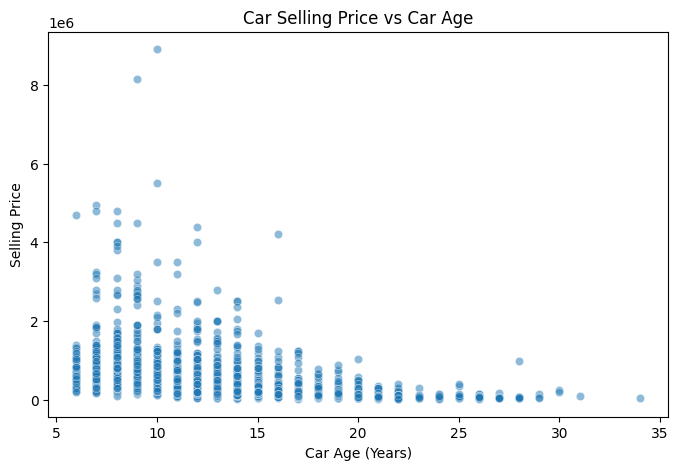

In [39]:
# Selling price vs car age
plt.figure(figsize=(8, 5))

sns.scatterplot(x='car_age', y='selling_price', data=df, alpha=0.5)

plt.title('Car Selling Price vs Car Age')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price')

plt.show()

"The scatter plot indicates a negative relationship between car age and selling price. As the age of a car increases, its selling price generally decreases. However, some variations exist due to factors such as brand, fuel type, and kilometres driven."

Correlation heatmap

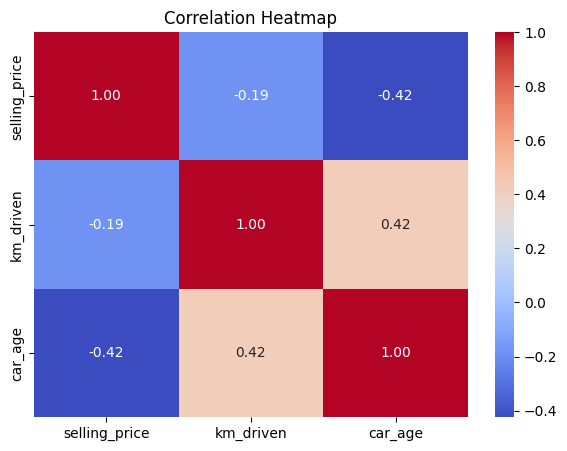

In [40]:
# Correlation between numerical features
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[['selling_price', 'km_driven', 'car_age']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

### Observation

- Selling price and car age have a moderate negative correlation (-0.42), indicating that older cars generally have lower selling prices.
- Selling price and kilometres driven have a weak negative correlation (-0.19), suggesting that cars driven for more kilometres tend to have slightly lower selling prices.
- Car age and kilometres driven have a positive correlation (0.42), indicating that older cars generally tend to have higher kilometres driven.

Overall, car age has a stronger negative correlation with selling price than kilometres driven in this dataset.

In [41]:
# Select input features
X = df[['car_age', 'km_driven', 'fuel',
        'seller_type', 'transmission', 'owner', 'brand']]

# Select target variable
y = df['selling_price']

# Display the shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (3577, 7)
Target Shape: (3577,)


Encode categorical variables

In [42]:
# Convert categorical variables into numerical variables
X = pd.get_dummies(X, drop_first=True)

# Display the first 5 rows
X.head()

,car_age,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_OpelCorsa,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,19,70000,False,False,False,True,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
1,19,50000,False,False,False,True,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
2,14,100000,True,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
3,9,46000,False,False,False,True,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
4,12,141000,True,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False


Split the dataset

80% training data: Used to teach the model.

20% testing data: Used to evaluate how well the model predicts prices for unseen cars.

In [43]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (2861, 41)
Testing Features: (716, 41)
Training Target: (2861,)
Testing Target: (716,)


Train Linear Regression Model

In [44]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [45]:
# Predict car selling prices
y_pred_lr = lr_model.predict(X_test)

# Display actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_lr
})

comparison.head(10)

,Actual Price,Predicted Price
0,270000,5.275978e+05
1,525000,4.705123e+05
2,990000,9.542257e+05
3,3800000,2.035904e+06
4,229999,1.429045e+05
5,325000,3.766896e+05
6,210000,1.680083e+05
7,500000,5.307215e+05
8,790000,8.018287e+05
9,360000,4.180518e+05


Evaluate Linear Regression

In [46]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Display results
print("Linear Regression Performance")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression Performance
MAE: 180194.98702147818
RMSE: 385606.08609790285
R2 Score: 0.5384145989249234


Train Random Forest Regressor

In [47]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [48]:
# Predict car selling prices
y_pred_rf = rf_model.predict(X_test)

# Compare actual and predicted prices
comparison_rf = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_rf
})

comparison_rf.head(10)

,Actual Price,Predicted Price
0,270000,5.686140e+05
1,525000,4.641374e+05
2,990000,1.451920e+06
3,3800000,2.550650e+06
4,229999,2.410000e+05
5,325000,3.583231e+05
6,210000,1.814333e+05
7,500000,6.807019e+05
8,790000,8.924091e+05
9,360000,4.685700e+05


In [49]:
# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# Display results
print("Random Forest Performance")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Performance
MAE: 158587.06767489918
RMSE: 365133.52904739865
R2 Score: 0.5861263909095635


In [50]:
# Compare model performance
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R2 Score': [r2_lr, r2_rf]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,180194.987021,385606.086098,0.538415
1,Random Forest,158587.067675,365133.529047,0.586126


Conclusion so far: Random Forest Regressor is the better-performing model among the two we tested.

Its R² score is approximately 0.5861 (58.61%), compared with Linear Regression's 53.84%.

In [51]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Display top 10 important features
feature_importance.head(10)

,Feature,Importance
8,transmission_Manual,0.244025
0,car_age,0.224724
1,km_driven,0.137067
2,fuel_Diesel,0.062951
13,brand_Audi,0.052459
5,fuel_Petrol,0.050190
27,brand_Land Rover,0.040506
38,brand_Toyota,0.037443
6,seller_type_Individual,0.019788
14,brand_BMW,0.014141


"The feature importance analysis shows that transmission type, car age and kilometres driven are the three most influential features in the Random Forest model. This indicates that vehicle characteristics play an important role in predicting used car selling prices.

Visualize Feature Importance

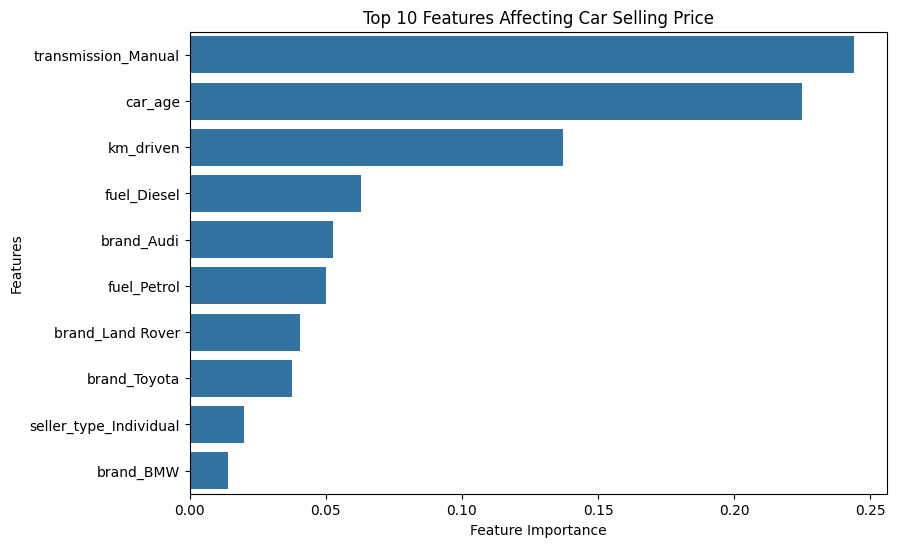

In [52]:
# Visualize top 10 important features
plt.figure(figsize=(9, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10)
)

plt.title('Top 10 Features Affecting Car Selling Price')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.show()

## Conclusion

In this project, machine learning techniques were used to predict used car selling prices based on features such as car age, kilometres driven, fuel type, transmission and brand.

Data cleaning, feature engineering and Exploratory Data Analysis (EDA) were performed before training two regression models: Linear Regression and Random Forest Regressor.

Random Forest performed better, achieving an R² Score of 0.5861 compared to 0.5384 for Linear Regression. Feature importance analysis identified transmission type, car age and kilometres driven as the most influential features.

Overall, this project provided practical experience in data preprocessing, data visualization and machine learning model development.